# SafeSpace – Hugging Face Leaderboard Lab (Part 1)
**Group 9 · Route A: Prompt Engineering**

**Goal:** test freely available LLMs before adding one to our Django app.

**Our use case:** SafeSpace is a self-care app. A user writes how they feel, and the model suggests **one small quest**
from our quest categories, plus a kind message.
```json
{"category": "Social", "quest": "Say hi to an old friend", "message": "A short message can mean a lot."}
```

In [ ]:
# Install packages (needed once per Colab session)
%pip install -q "transformers>=4.56" accelerate huggingface_hub pandas matplotlib
%pip install -q bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 14.8 MB/s eta 0:00:00


## 1. Models and weight download
We chose 15 models, grouped by **parameter size** (5 categories × 3 models).

In [ ]:
import shutil
from huggingface_hub import snapshot_download

MODELS = {
    "Tiny (< 0.5B)": [
        "Qwen/Qwen2.5-0.5B-Instruct",
        "Qwen/Qwen2-0.5B-Instruct",
        "HuggingFaceTB/SmolLM2-135M-Instruct",
    ],
    "Ultra-light (0.5-1.5B)": [
        "unsloth/Llama-3.2-1B-Instruct",
        "ibm-granite/granite-3.1-1b-a400m-instruct",
        "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    ],
    "Small (1.5-2.5B)": [
        "Qwen/Qwen2.5-1.5B-Instruct",
        "tiiuae/Falcon3-1B-Instruct",
        "HuggingFaceTB/SmolLM2-1.7B-Instruct",
    ],
    "Medium (2.5-3.5B)": [
        "Qwen/Qwen2.5-3B-Instruct",
        "tiiuae/Falcon3-3B-Instruct",
        "unsloth/Llama-3.2-3B-Instruct",
    ],
    "Large (3.5-8B)": [
        "tiiuae/Falcon3-7B-Instruct",
        "microsoft/Phi-4-mini-instruct",
        "microsoft/Phi-3-mini-128k-instruct",
    ],
}

WEIGHT_FILES = ["*.json", "*.safetensors", "*.txt", "*.model", "*.jinja", "*.tiktoken"]


def download_weights(name):
    return snapshot_download(name, allow_patterns=WEIGHT_FILES)


free_gb = shutil.disk_usage(".").free / 1e9
DOWNLOAD_ALL_NOW = free_gb > 85
print(f"Free disk: {free_gb:.0f} GB")

if DOWNLOAD_ALL_NOW:
    for category, names in MODELS.items():
        for name in names:
            print(f"Downloading {name} ...")
            download_weights(name)
    print("All weights downloaded.")
else:
    print("Not enough space for all 15 at once: each model will be downloaded when tested, then deleted.")

Free disk: 75 GB
Not enough space for all 15 at once: each model will be downloaded when tested, then deleted.


## 2. Research & categorization
Scores from the Open LLM Leaderboard.


| Category | Model | Company | Params | ≈ Size | Rank | IFEval | BBH |
|---|---|---|---|---|---|---|---|
| Tiny (< 0.5B) | Qwen/Qwen2.5-0.5B-Instruct | Alibaba | 0.49B | 1 GB | 2350 | 31.5 | 8.2 |
| | Qwen/Qwen2-0.5B-Instruct | Alibaba | 0.49B | 1 GB | 2534 | 22.5 | 5.9 |
| | HuggingFaceTB/SmolLM2-135M-Instruct | Hugging Face | 0.13B | 0.3 GB | 2542 | 28.8 | 4.7 |
| Ultra-light (0.5–1.5B) | unsloth/Llama-3.2-1B-Instruct | Meta (via Unsloth) | 1.24B | 2.5 GB | 2080 | 58.1 | 8.3 |
| | ibm-granite/granite-3.1-1b-a400m-instruct | IBM | 1.33B | 2.7 GB | 2348 | 46.9 | 6.2 |
| | TinyLlama/TinyLlama-1.1B-Chat-v1.0 | TinyLlama | 1.10B | 2.2 GB | 2822 | 6.0 | 4.0 |
| Small (1.5–2.5B) | Qwen/Qwen2.5-1.5B-Instruct | Alibaba | 1.54B | 3 GB | 1734 | 44.8 | 19.8 |
| | tiiuae/Falcon3-1B-Instruct | TII | 1.67B | 3.3 GB | 1943 | 55.6 | 13.0 |
| | HuggingFaceTB/SmolLM2-1.7B-Instruct | Hugging Face | 1.71B | 3.4 GB | 2044 | 53.7 | 10.9 |
| Medium (2.5–3.5B) | Qwen/Qwen2.5-3B-Instruct | Alibaba | 3.09B | 6 GB | 835 | 64.7 | 25.8 |
| | tiiuae/Falcon3-3B-Instruct | TII | 3.23B | 6.5 GB | 871 | 69.8 | 26.3 |
| | unsloth/Llama-3.2-3B-Instruct | Meta (via Unsloth) | 3.21B | 6.4 GB | 1046* | 73.9* | 24.1* |
| Large (3.5–8B) | tiiuae/Falcon3-7B-Instruct | TII | 7.46B | 15 GB | 340 | 76.1 | 37.9 |
| | microsoft/Phi-4-mini-instruct | Microsoft | 3.84B | 7.7 GB | 676 | 73.8 | 38.7 |
| | microsoft/Phi-3-mini-128k-instruct | Microsoft | 3.82B | 7.6 GB | 889 | 59.8 | 37.1 |

## 3. Loading and running a model


In [ ]:
import gc
import json
import time

import pandas as pd
import torch
from huggingface_hub import scan_cache_dir
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print("Device:", DEVICE)

CATEGORY_OF = {name: category for category, names in MODELS.items() for name in names}


def load_model(name):
    path = download_weights(name)
    tokenizer = AutoTokenizer.from_pretrained(path)
    big = "7B" in name or "8B" in name
    if DEVICE == "cuda" and big:
        model = AutoModelForCausalLM.from_pretrained(
            path, quantization_config=BitsAndBytesConfig(load_in_4bit=True), device_map="auto"
        )
    else:
        dtype = torch.float32 if DEVICE == "cpu" else torch.float16
        model = AutoModelForCausalLM.from_pretrained(path, dtype=dtype).to(DEVICE)
    model.eval()
    return tokenizer, model


def free_memory(name):
    """Call after `del model`: clears GPU memory, and the disk copy if it was downloaded on demand."""
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    if not DOWNLOAD_ALL_NOW:
        cache = scan_cache_dir()
        for repo in cache.repos:
            if repo.repo_id == name:
                cache.delete_revisions(*[r.commit_hash for r in repo.revisions]).execute()


def generate(tokenizer, model, messages, max_new_tokens=150):
    """Return (answer text, seconds)."""
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    start = time.time()
    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id,
        )
    seconds = time.time() - start
    answer = tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return answer.strip(), seconds

Device: cuda


## 4. Fixed test inputs and prompt
The same instruction and the same 5 inputs are used for each model, so the comparison is fair.
The categories and example quests come from our SafeSpace database.

In [ ]:
CATEGORIES = ["Diet & Wellness", "General Self-Care", "Learning", "Social"]

SYSTEM_PROMPT = (
    "You are SafeSpace, a gentle self-care assistant. "
    "Read how the user feels and suggest ONE small, doable quest. "
    "Answer ONLY with a JSON object with exactly these keys: "
    f'"category" (one of {CATEGORIES}), "quest" (a short action), '
    '"message" (one kind sentence). No other text.'
)

TEST_INPUTS = [
    "I'm so stressed about my exams next week.",
    "I feel lonely since moving to a new city.",
    "I haven't been sleeping well and I'm always tired.",
    "I skipped lunch again because I was too busy.",
    "I feel unmotivated and bored with everything.",
]

## 5. Evaluation criteria (decided by our group)
| Criterion | How it is measured |
|---|---|
| **Valid JSON** | `json.loads` succeeds (code fences are allowed) |
| **Right keys** | exactly `category`, `quest`, `message` |
| **Valid category** | category is one of our 4 SafeSpace categories |
| **Speed** | seconds per answer |

**Score** = average of the first three (0–100%). Speed is used as the tie-breaker.

In [ ]:
def parse_json(answer):
    text = answer.strip()
    if text.startswith("```"):
        text = text.strip("`").removeprefix("json").strip()
    start, end = text.find("{"), text.rfind("}")
    if start == -1 or end == -1:
        return None
    try:
        data = json.loads(text[start:end + 1])
    except json.JSONDecodeError:
        return None
    return data if isinstance(data, dict) else None


def evaluate(answer):
    data = parse_json(answer)
    valid_json = data is not None
    right_keys = valid_json and set(data) == {"category", "quest", "message"}
    valid_category = valid_json and data.get("category") in CATEGORIES
    return {
        "valid_json": valid_json,
        "right_keys": right_keys,
        "valid_category": valid_category,
        "score": (valid_json + right_keys + valid_category) / 3 * 100,
    }


evaluate('{"category": "Social", "quest": "Call a friend", "message": "You matter."}')

{'valid_json': True,
 'right_keys': True,
 'valid_category': True,
 'score': 100.0}

## 6. Matrix test: all 15 models × 5 inputs (zero-shot)
Each model gets the system prompt and the user's text, with no examples.

In [ ]:
def zero_shot(user_text):
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_text},
    ]


matrix_rows = []
for category, names in MODELS.items():
    for name in names:
        print(f"Testing {name} ...")
        try:
            tokenizer, model = load_model(name)
        except Exception as exc:
            print(f"  could not load: {exc}")
            continue
        for text in TEST_INPUTS:
            answer, seconds = generate(tokenizer, model, zero_shot(text))
            matrix_rows.append({
                "category": category, "model": name, "input": text,
                "answer": answer, "seconds": round(seconds, 2), **evaluate(answer),
            })
        del tokenizer, model
        free_memory(name)

matrix = pd.DataFrame(matrix_rows)
print(f"\n{len(matrix)} answers collected")

Testing Qwen/Qwen2.5-0.5B-Instruct ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Testing Qwen/Qwen2-0.5B-Instruct ...


...

Testing microsoft/Phi-3-mini-128k-instruct ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]


75 answers collected


In [ ]:
pd.set_option("display.max_colwidth", 120)
matrix[["model", "input", "answer"]]

,model,input,answer
0,Qwen/Qwen2.5-0.5B-Instruct,I'm so stressed about my exams next week.,"{\n ""category"": ""General Self-Care"",\n ""quest"": ""Take a deep breath and practice mindfulness meditation for at lea..."
1,Qwen/Qwen2.5-0.5B-Instruct,I feel lonely since moving to a new city.,"{\n ""category"": ""General Self-Care"",\n ""quest"": ""Reach out to friends or join a support group in your new city."",\..."
2,Qwen/Qwen2.5-0.5B-Instruct,I haven't been sleeping well and I'm always tired.,"{\n ""category"": ""General Self-Care"",\n ""quest"": ""Create a bedtime routine that includes relaxation activities like..."
3,Qwen/Qwen2.5-0.5B-Instruct,I skipped lunch again because I was too busy.,"{""category"": ""General Self-Care"", ""quest"": ""Take a moment to eat your lunch or snack if you're feeling hungry."", ""me..."
4,Qwen/Qwen2.5-0.5B-Instruct,I feel unmotivated and bored with everything.,"{""category"": ""General Self-Care"", ""quest"": ""Create a daily schedule that includes activities you enjoy and find mean..."
...,...,...,...
70,microsoft/Phi-3-mini-128k-instruct,I'm so stressed about my exams next week.,"```json\n\n{\n\n ""category"": ""General Self-Care"",\n\n ""quest"": ""Take a 10-minute break every hour while studying t..."
71,microsoft/Phi-3-mini-128k-instruct,I feel lonely since moving to a new city.,"```json\n\n{\n\n ""category"": ""Social"",\n\n ""quest"": ""Join a local book club or meetup group."",\n\n ""message"": ""Fi..."
72,microsoft/Phi-3-mini-128k-instruct,I haven't been sleeping well and I'm always tired.,"```json\n\n{\n\n ""category"": ""General Self-Care"",\n\n ""quest"": ""Establish a relaxing bedtime routine"",\n\n ""messa..."
73,microsoft/Phi-3-mini-128k-instruct,I skipped lunch again because I was too busy.,"```json\n\n{\n\n ""category"": ""Diet & Wellness"",\n\n ""quest"": ""Prepare a healthy snack for later."",\n\n ""message"":..."


### Matrix results per model

In [ ]:
model_summary = (
    matrix.groupby(["category", "model"], sort=False)
    .agg(score=("score", "mean"), valid_json=("valid_json", "mean"),
         right_keys=("right_keys", "mean"), valid_category=("valid_category", "mean"),
         avg_seconds=("seconds", "mean"))
)
model_summary[["valid_json", "right_keys", "valid_category"]] *= 100
model_summary = model_summary.round(1)
model_summary

score  \
category               model                                              
Tiny (< 0.5B)          Qwen/Qwen2.5-0.5B-Instruct                 100.0   
                       Qwen/Qwen2-0.5B-Instruct                    93.3   
                       HuggingFaceTB/SmolLM2-135M-Instruct         20.0   
Ultra-light (0.5-1.5B) unsloth/Llama-3.2-1B-Instruct               40.0   
                       ibm-granite/granite-3.1-1b-a400m-instruct  100.0   
                       TinyLlama/TinyLlama-1.1B-Chat-v1.0          53.3   
Small (1.5-2.5B)       Qwen/Qwen2.5-1.5B-Instruct                 100.0   
                       tiiuae/Falcon3-1B-Instruct                 100.0   
                       HuggingFaceTB/SmolLM2-1.7B-Instruct         80.0   
Medium (2.5-3.5B)      Qwen/Qwen2.5-3B-Instruct                   100.0   
                       tiiuae/Falcon3-3B-Instruct                  20.0   
                       unsloth/Llama-3.2-3B-Instruct              100.0   
Large (3.5-8B)         tiiuae/Falcon3-7B-Instruct                 100.0   
                       microsoft/Phi-4-mini-instruct              100.0   
                       microsoft/Phi-3-mini-128k-instruct         100.0   

                                                                  valid_json  \
category               model                                                   
Tiny (< 0.5B)          Qwen/Qwen2.5-0.5B-Instruct                      100.0   
                       Qwen/Qwen2-0.5B-Instruct                        100.0   
                       HuggingFaceTB/SmolLM2-135M-Instruct              20.0   
Ultra-light (0.5-1.5B) unsloth/Llama-3.2-1B-Instruct                    40.0   
                       ibm-granite/granite-3.1-1b-a400m-instruct       100.0   
                       TinyLlama/TinyLlama-1.1B-Chat-v1.0               60.0   
Small (1.5-2.5B)       Qwen/Qwen2.5-1.5B-Instruct                      100.0   
                       tiiuae/Falcon3-1B-Instruct                      100.0   
                       HuggingFaceTB/SmolLM2-1.7B-Instruct              80.0   
Medium (2.5-3.5B)      Qwen/Qwen2.5-3B-Instruct                        100.0   
                       tiiuae/Falcon3-3B-Instruct                       20.0   
                       unsloth/Llama-3.2-3B-Instruct                   100.0   
Large (3.5-8B)         tiiuae/Falcon3-7B-Instruct                      100.0   
                       microsoft/Phi-4-mini-instruct                   100.0   
                       microsoft/Phi-3-mini-128k-instruct              100.0   

                                                                  right_keys  \
category               model                                                   
Tiny (< 0.5B)          Qwen/Qwen2.5-0.5B-Instruct                      100.0   
                       Qwen/Qwen2-0.5B-Instruct                        100.0   
                       HuggingFaceTB/SmolLM2-135M-Instruct              20.0   
Ultra-light (0.5-1.5B) unsloth/Llama-3.2-1B-Instruct                    40.0   
                       ibm-granite/granite-3.1-1b-a400m-instruct       100.0   
                       TinyLlama/TinyLlama-1.1B-Chat-v1.0               40.0   
Small (1.5-2.5B)       Qwen/Qwen2.5-1.5B-Instruct                      100.0   
                       tiiuae/Falcon3-1B-Instruct                      100.0   
                       HuggingFaceTB/SmolLM2-1.7B-Instruct              80.0   
Medium (2.5-3.5B)      Qwen/Qwen2.5-3B-Instruct                        100.0   
                       tiiuae/Falcon3-3B-Instruct                       20.0   
                       unsloth/Llama-3.2-3B-Instruct                   100.0   
Large (3.5-8B)         tiiuae/Falcon3-7B-Instruct                      100.0   
                       microsoft/Phi-4-mini-instruct                   100.0   
                       microsoft/Phi-3-mini-128k-instruct              100.0   

                                                                  va

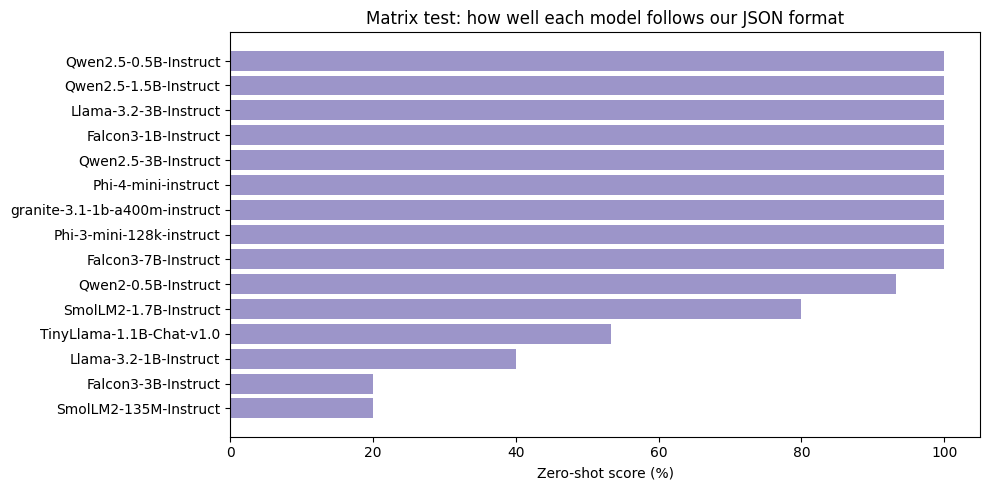

Best model per category:
              category                                     model  score  avg_seconds
         Tiny (< 0.5B)                Qwen/Qwen2.5-0.5B-Instruct  100.0          2.2
      Small (1.5-2.5B)                Qwen/Qwen2.5-1.5B-Instruct  100.0          2.3
     Medium (2.5-3.5B)             unsloth/Llama-3.2-3B-Instruct  100.0          2.6
        Large (3.5-8B)             microsoft/Phi-4-mini-instruct  100.0          3.7
Ultra-light (0.5-1.5B) ibm-granite/granite-3.1-1b-a400m-instruct  100.0          4.4


In [ ]:
import matplotlib.pyplot as plt

ranked = model_summary.reset_index().sort_values(["score", "avg_seconds"], ascending=[False, True])
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(ranked["model"].str.split("/").str[1], ranked["score"], color="#9C95C9")
ax.invert_yaxis()
ax.set_xlabel("Zero-shot score (%)")
ax.set_title("Matrix test: how well each model follows our JSON format")
plt.tight_layout()
plt.show()

print("Best model per category:")
print(ranked.groupby("category", sort=False).head(1)[["category", "model", "score", "avg_seconds"]].to_string(index=False))

## 7. Route A: prompt engineering on the top models
We take the **top 3 models** from the matrix test and try four prompt styles.
Examples are given as earlier user/assistant turns, so the model can copy the format:

| Style | Examples in the prompt |
|---|---|
| Zero-shot | 0 |
| One-shot | 1 |
| Few-shot | 3 |
| Many-shot | 8 |

In [ ]:
EXAMPLES = [
    ("I ate junk food all day.",
     {"category": "Diet & Wellness", "quest": "Drink 2000 c.c. of water", "message": "One healthy step today is enough."}),
    ("My mind is racing and I can't focus.",
     {"category": "General Self-Care", "quest": "Observe the clouds", "message": "Let yourself slow down for a moment."}),
    ("I miss my old friends.",
     {"category": "Social", "quest": "Say hi to an old friend", "message": "A short message can mean a lot."}),
    ("I feel stuck and want to grow.",
     {"category": "Learning", "quest": "Read a book for 15 minutes", "message": "A few pages can open a new door."}),
    ("I sat at my desk all day.",
     {"category": "Diet & Wellness", "quest": "Take a walk", "message": "Your body will thank you for moving."}),
    ("I stayed up too late again.",
     {"category": "General Self-Care", "quest": "Go to bed before 10 p.m.", "message": "Rest is not lazy; it is care."}),
    ("Nobody texted me today.",
     {"category": "Social", "quest": "Send a kind message to a classmate", "message": "Reaching out is brave."}),
    ("I want to learn something new.",
     {"category": "Learning", "quest": "Watch a short tutorial", "message": "Curiosity is a great place to start."}),
]

PROMPT_STYLES = {"zero-shot": 0, "one-shot": 1, "few-shot": 3, "many-shot": 8}


def build_prompt(user_text, n_examples):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    for example_text, example_answer in EXAMPLES[:n_examples]:
        messages.append({"role": "user", "content": example_text})
        messages.append({"role": "assistant", "content": json.dumps(example_answer)})
    messages.append({"role": "user", "content": user_text})
    return messages


build_prompt(TEST_INPUTS[0], 1)  # what a one-shot prompt looks like

[{'role': 'system',
  'content': 'You are SafeSpace, a gentle self-care assistant. Read how the user feels and suggest ONE small, doable quest. Answer ONLY with a JSON object with exactly these keys: "category" (one of [\'Diet & Wellness\', \'General Self-Care\', \'Learning\', \'Social\']), "quest" (a short action), "message" (one kind sentence). No other text.'},
 {'role': 'user', 'content': 'I ate junk food all day.'},
 {'role': 'assistant',
  'content': '{"category": "Diet & Wellness", "quest": "Drink 2000 c.c. of water", "message": "One healthy step today is enough."}'},
 {'role': 'user', 'content': "I'm so stressed about my exams next week."}]

In [ ]:
TOP_N = 3
top_models = ranked.head(TOP_N)["model"].tolist()
print("Top models:", top_models)

route_rows = []
for name in top_models:
    print(f"Prompting {name} ...")
    tokenizer, model = load_model(name)
    for style, n in PROMPT_STYLES.items():
        for text in TEST_INPUTS:
            answer, seconds = generate(tokenizer, model, build_prompt(text, n))
            route_rows.append({
                "model": name, "style": style, "input": text,
                "answer": answer, "seconds": round(seconds, 2), **evaluate(answer),
            })
    del tokenizer, model
    free_memory(name)

route = pd.DataFrame(route_rows)
route[["model", "style", "input", "answer"]]

Top models: ['Qwen/Qwen2.5-0.5B-Instruct', 'Qwen/Qwen2.5-1.5B-Instruct', 'unsloth/Llama-3.2-3B-Instruct']
Prompting Qwen/Qwen2.5-0.5B-Instruct ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Prompting Qwen/Qwen2.5-1.5B-Instruct ...


...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=150) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=150) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=150) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=150) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https:/

,model,style,input,answer
0,Qwen/Qwen2.5-0.5B-Instruct,zero-shot,I'm so stressed about my exams next week.,"{\n ""category"": ""General Self-Care"",\n ""quest"": ""Take a deep breath and practice mindfulness meditation for at lea..."
1,Qwen/Qwen2.5-0.5B-Instruct,zero-shot,I feel lonely since moving to a new city.,"{\n ""category"": ""General Self-Care"",\n ""quest"": ""Reach out to friends or join a support group in your new city."",\..."
2,Qwen/Qwen2.5-0.5B-Instruct,zero-shot,I haven't been sleeping well and I'm always tired.,"{\n ""category"": ""General Self-Care"",\n ""quest"": ""Create a bedtime routine that includes relaxation activities like..."
3,Qwen/Qwen2.5-0.5B-Instruct,zero-shot,I skipped lunch again because I was too busy.,"{""category"": ""General Self-Care"", ""quest"": ""Take a moment to eat your lunch or snack if you're feeling hungry."", ""me..."
4,Qwen/Qwen2.5-0.5B-Instruct,zero-shot,I feel unmotivated and bored with everything.,"{""category"": ""General Self-Care"", ""quest"": ""Create a daily schedule that includes activities you enjoy and find mean..."
5,Qwen/Qwen2.5-0.5B-Instruct,one-shot,I'm so stressed about my exams next week.,"{""category"": ""General Self-Care"", ""quest"": ""Take a deep breath and practice mindfulness exercises."", ""message"": ""Tak..."
6,Qwen/Qwen2.5-0.5B-Instruct,one-shot,I feel lonely since moving to a new city.,"{""category"": ""General Self-Care"", ""quest"": ""Talk to someone about your feelings."", ""message"": ""It's okay to feel alo..."
7,Qwen/Qwen2.5-0.5B-Instruct,one-shot,I haven't been sleeping well and I'm always tired.,"{""category"": ""General Self-Care"", ""quest"": ""Go to bed early and get up early."", ""message"": ""Sleeping well is essenti..."
8,Qwen/Qwen2.5-0.5B-Instruct,one-shot,I skipped lunch again because I was too busy.,"{""category"": ""General Self-Care"", ""quest"": ""Take a walk or go for a run."", ""message"": ""A little exercise can help yo..."
9,Qwen/Qwen2.5-0.5B-Instruct,one-shot,I feel unmotivated and bored with everything.,"{""category"": ""General Self-Care"", ""quest"": ""Go for a walk or take a yoga class."", ""message"": ""Your body needs exerci..."


### Route A results

In [ ]:
style_summary = (
    route.groupby(["model", "style"], sort=False)
    .agg(score=("score", "mean"), valid_json=("valid_json", "mean"),
         right_keys=("right_keys", "mean"), valid_category=("valid_category", "mean"),
         avg_seconds=("seconds", "mean"))
)
style_summary[["valid_json", "right_keys", "valid_category"]] *= 100
style_summary.round(1)

score  valid_json  right_keys  \
model                         style                                      
Qwen/Qwen2.5-0.5B-Instruct    zero-shot  100.0       100.0       100.0   
                              one-shot   100.0       100.0       100.0   
                              few-shot   100.0       100.0       100.0   
                              many-shot  100.0       100.0       100.0   
Qwen/Qwen2.5-1.5B-Instruct    zero-shot  100.0       100.0       100.0   
                              one-shot   100.0       100.0       100.0   
                              few-shot   100.0       100.0       100.0   
                              many-shot  100.0       100.0       100.0   
unsloth/Llama-3.2-3B-Instruct zero-shot  100.0       100.0       100.0   
                              one-shot   100.0       100.0       100.0   
                              few-shot   100.0       100.0       100.0   
                              many-shot  100.0       100.0       100.0   

                                         valid_category  avg_seconds  
model                         style                                   
Qwen/Qwen2.5-0.5B-Instruct    zero-shot           100.0          1.9  
                              one-shot            100.0          1.5  
                              few-shot            100.0          1.2  
                              many-shot           100.0          1.1  
Qwen/Qwen2.5-1.5B-Instruct    zero-shot           100.0          2.4  
                              one-shot            100.0          1.6  
                              few-shot            100.0          1.4  
                              many-shot           100.0          1.4  
unsloth/Llama-3.2-3B-Instruct zero-shot           100.0          2.9  
                              one-shot            100.0          1.5  
                              few-shot            100.0          1.5  
                              many-shot           100.0          1.7

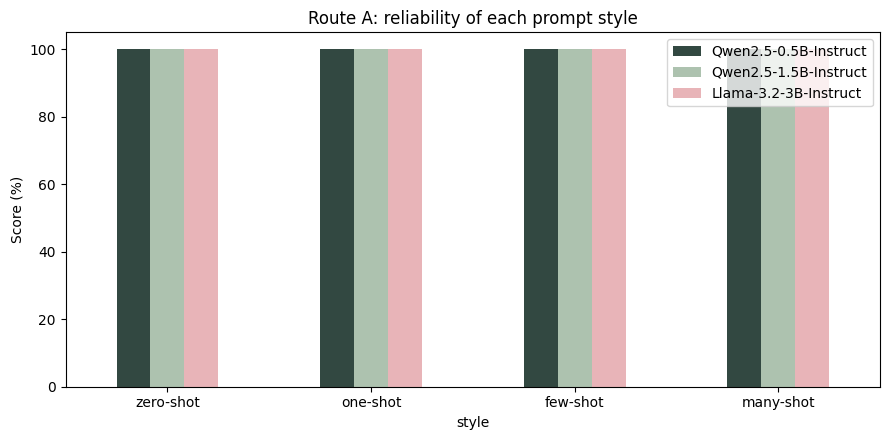

Average score per prompt style (top models):
style
zero-shot    100.0
one-shot     100.0
few-shot     100.0
many-shot    100.0

Most reliable style: zero-shot


In [ ]:
pivot = route.pivot_table(index="style", columns="model", values="score", aggfunc="mean", sort=False)
pivot.columns = [c.split("/")[1] for c in pivot.columns]

ax = pivot.plot(kind="bar", figsize=(9, 4.5), rot=0, color=["#324841", "#ADC2AF", "#E8B4B8"][:len(pivot.columns)])
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 105)
ax.set_title("Route A: reliability of each prompt style")
plt.tight_layout()
plt.show()

overall = route.groupby("style", sort=False)["score"].mean().round(1)
print("Average score per prompt style (top models):")
print(overall.to_string())
print(f"\nMost reliable style: {overall.idxmax()}")

## 8. Conclusion

- **Matrix test:** The top models in the matrix test are:
  - **Tiny:** Qwen/Qwen2.5-0.5B-Instruct with a score of 100 and avg_sec of 2.2
  - **Small:** Qwen/Qwen2.5-1.5B-Instruct with a score of 100 and avg_sec of 2.3
  - **Medium:** unsloth/Llama-3.2-3B-Instruct with a score of 100 and avg_sec of 2.6
  - **Large:** microsoft/Phi-4-mini-Instruct with a score of 100 and avg_sec of 3.7
  - **Ultra-Light:** ibm-granite/granite-3.1-1b-a400m-instruct with a score of 100 and avg_sec of 4.4
- **Route A:** Each prompt style was fairly reliable, resulting in good scores all around and fairly good results in speed. They all scored 100, but we came to our decision that the few-shot was the best as it resulted in the fastest times overall. Examining the table also reveals that the few-shot had the best responses in our opinions.
- **Choice for Django:** Due to size, speed, score, and it's ability with a few-shot style, the model we selected is the Qwen/Qwen2.5-0.5B-Instruct.